# 02 · Waktu keputusan, volatilitas, dan label

**Bab 3 Subbab 3.5.**

- Waktu keputusan bar ke-*t*: $\tau_t = o_t + 1$ jam (bar sudah selesai).
- Log-return: $r_t = \ln(C_t / C_{t-1})$, dihitung di dalam segmen.
- Volatilitas 24 bar: $\sigma_{t,24}$ = simpangan baku **sampel** (pembagi 23) dari $r_t, \dots, r_{t-23}$.
- Target: $q_{t+1} = \ln(C_{t+1} / C_t)$ dan ambang $\delta_t = 0{,}5 \cdot \sigma_{t,24}$.

| Kondisi | Label |
|---|---|
| $q_{t+1} > \delta_t$ | BUY |
| $q_{t+1} < -\delta_t$ | SELL |
| selain itu | HOLD |

Observasi layak diberi label hanya jika bar berikutnya dibuka **tepat** 1 jam kemudian, di segmen yang sama, tidak
setelah gap, dan $\sigma_{t,24}$ positif dan terhingga. Pengali 0,25 dan 1,0 dihitung sebagai sensitivitas terpisah.

**Input:** `01_harga.parquet` · **Output:** `02_label.parquet`

In [1]:
import tomllib
from pathlib import Path

# Cari folder proyek (folder yang memuat configs/phase4-p0.toml) agar notebook bisa dijalankan dari mana saja.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs/phase4-p0.toml").exists())
CFG = tomllib.loads((ROOT / "configs/phase4-p0.toml").read_text(encoding="utf-8"))
OUT = ROOT / "data/interim/phase4-p0"     # folder hasil; diabaikan Git karena memuat data vendor
OUT.mkdir(parents=True, exist_ok=True)

In [2]:
import numpy as np
import pandas as pd

df = pd.read_parquet(OUT / "01_harga.parquet")
W = CFG["label"]["volatility_window"]

df["decision_time"] = df["time"] + pd.Timedelta(hours=CFG["label"]["horizon_hours"])

# r_t di dalam segmen: bar pertama segmen tidak punya r_t (indikator dimulai ulang)
df["r"] = np.log(df["close"] / df.groupby("segment_id")["close"].shift(1))
df["sigma_24"] = df.groupby("segment_id")["r"].transform(lambda s: s.rolling(W).std(ddof=1))
df[["time", "close", "r", "sigma_24"]].iloc[20:28]

,time,close,r,sigma_24
20,2020-01-03 03:00:00+00:00,1534.89,0.002845,NaN
21,2020-01-03 04:00:00+00:00,1538.19,0.002148,NaN
22,2020-01-03 05:00:00+00:00,1538.59,0.000260,NaN
23,2020-01-03 06:00:00+00:00,1538.73,0.000091,NaN
24,2020-01-03 07:00:00+00:00,1541.42,0.001747,0.001239
25,2020-01-03 08:00:00+00:00,1541.18,-0.000156,0.001249
26,2020-01-03 09:00:00+00:00,1543.39,0.001433,0.001261
27,2020-01-03 10:00:00+00:00,1544.24,0.000551,0.001203


### Contoh hitung manual σ24 untuk satu bar

Ambil 24 log-return terakhir, hitung rata-rata, lalu akar dari jumlah kuadrat simpangan dibagi 23.

In [3]:
i = 30
r24 = df["r"].iloc[i - 23 : i + 1].to_numpy()
manual = np.sqrt(((r24 - r24.mean()) ** 2).sum() / 23)
print(f"σ24 manual = {manual:.10f}")
print(f"σ24 kode   = {df['sigma_24'].iloc[i]:.10f}")
assert np.isclose(manual, df["sigma_24"].iloc[i])

σ24 manual = 0.0012043755
σ24 kode   = 0.0012043755


## 2. Target dan kelayakan label

In [4]:
bar_berikut = df["time"].shift(-1)
df["target_end_time"] = df["decision_time"] + pd.Timedelta(hours=1)   # τ_{t+1} = o_t + 2 jam
df["q"] = np.log(df["close"].shift(-1) / df["close"])

df["target_layak"] = (
    (bar_berikut - df["time"] == pd.Timedelta(hours=1))          # bar berikutnya tepat 1 jam kemudian
    & (df["segment_id"].shift(-1) == df["segment_id"])            # masih di segmen yang sama
    & ~df["setelah_gap"].shift(-1, fill_value=True)               # tidak melompati gap
    & np.isfinite(df["sigma_24"]) & (df["sigma_24"] > 0)
)


def beri_label(q, delta):
    return np.select([q > delta, q < -delta], ["BUY", "SELL"], "HOLD")


AMBANG = [CFG["label"]["threshold_utama"], *CFG["label"]["threshold_sensitivitas"]]
for m in AMBANG:
    kolom = "label_" + str(m).replace(".", "p")
    df[kolom] = pd.Series(beri_label(df["q"], m * df["sigma_24"]), index=df.index).where(df["target_layak"])

print("Bar dengan label layak:", int(df["target_layak"].sum()), "dari", len(df))
df.loc[df["target_layak"], ["time", "q", "sigma_24", "label_0p5"]].head()

Bar dengan label layak: 36872 dari 38799


,time,q,sigma_24,label_0p5
24,2020-01-03 07:00:00+00:00,-0.000156,0.001239,HOLD
25,2020-01-03 08:00:00+00:00,0.001433,0.001249,BUY
26,2020-01-03 09:00:00+00:00,0.000551,0.001261,HOLD
27,2020-01-03 10:00:00+00:00,0.001624,0.001203,BUY
28,2020-01-03 11:00:00+00:00,0.001092,0.001216,BUY


### Contoh: mengapa sebuah bar diberi BUY/HOLD/SELL

In [5]:
contoh = df[df["target_layak"]].iloc[[0, 1, 2, 3, 4]].copy()
contoh["delta_0p5"] = 0.5 * contoh["sigma_24"]
contoh[["time", "close", "q", "delta_0p5", "label_0p5"]]

,time,close,q,delta_0p5,label_0p5
24,2020-01-03 07:00:00+00:00,1541.42,-0.000156,0.000620,HOLD
25,2020-01-03 08:00:00+00:00,1541.18,0.001433,0.000624,BUY
26,2020-01-03 09:00:00+00:00,1543.39,0.000551,0.000630,HOLD
27,2020-01-03 10:00:00+00:00,1544.24,0.001624,0.000602,BUY
28,2020-01-03 11:00:00+00:00,1546.75,0.001092,0.000608,BUY


## 3. Distribusi kelas per ambang

HOLD makin banyak saat ambang makin lebar. Proporsi ini dihitung pada seluruh bar berlabel (sebelum syarat pemanasan
fitur), hanya sebagai gambaran.

In [6]:
distribusi = pd.DataFrame({
    f"ambang {m:g}·σ24": df["label_" + str(m).replace(".", "p")].value_counts(normalize=True).reindex(["BUY", "HOLD", "SELL"])
    for m in AMBANG
}).round(3)
distribusi

,ambang 0.5·σ24,ambang 0.25·σ24,ambang 1·σ24
BUY,0.268,0.378,0.128
HOLD,0.481,0.262,0.749
SELL,0.251,0.360,0.123


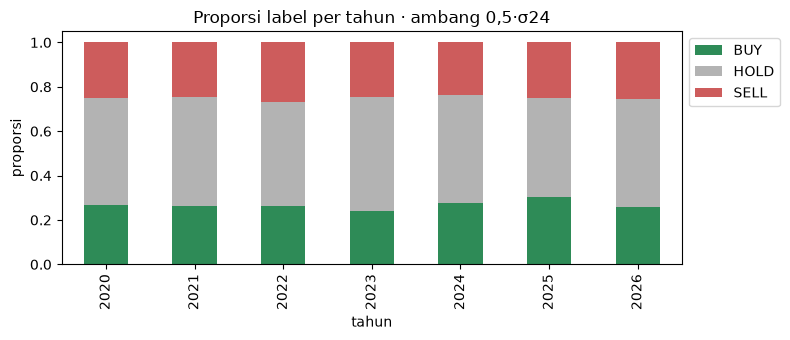

In [7]:
import matplotlib.pyplot as plt

tahunan = (df.loc[df["target_layak"]].assign(tahun=lambda d: d["time"].dt.year)
           .groupby("tahun")["label_0p5"].value_counts(normalize=True).unstack()[["BUY", "HOLD", "SELL"]])
ax = tahunan.plot.bar(stacked=True, figsize=(8, 3.5), color=["seagreen", "0.7", "indianred"])
ax.set_ylabel("proporsi")
ax.set_title("Proporsi label per tahun · ambang 0,5·σ24")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()

In [8]:
kolom_label = [c for c in df.columns if c.startswith("label_")]
df[["time", "decision_time", "target_end_time", "segment_id", "r", "sigma_24", "q", "target_layak", *kolom_label]].to_parquet(
    OUT / "02_label.parquet", index=False)
print("Tersimpan:", (OUT / "02_label.parquet").relative_to(ROOT))

Tersimpan: data/interim/phase4-p0/02_label.parquet
